In [26]:
import pandas as pd 
import numpy as np 
import re
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score ,classification_report

from tensorflow.keras.preprocessing.text import Tokenizer
from tensorflow.keras.preprocessing.sequence  import pad_sequences

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense ,Input,Embedding ,LSTM , Dropout
from tensorflow.keras.callbacks import EarlyStopping


In [ ]:
df = pd.read_csv(r"IMDB Dataset.csv")
print(type(df))
df.shape


<class 'pandas.DataFrame'>


(50000, 2)

In [28]:
df.head(10)

,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive
5,"Probably my all-time favorite movie, a story o...",positive
6,I sure would like to see a resurrection of a u...,positive
7,"This show was an amazing, fresh & innovative i...",negative
8,Encouraged by the positive comments about this...,negative
9,If you like original gut wrenching laughter yo...,positive


In [29]:
df.describe()

,review,sentiment
count,50000,50000
unique,49582,2
top,Loved today's show!!! It was a variety and not...,positive
freq,5,25000


In [30]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 2 columns):
 #   Column     Non-Null Count  Dtype
---  ------     --------------  -----
 0   review     50000 non-null  str  
 1   sentiment  50000 non-null  str  
dtypes: str(2)
memory usage: 781.4 KB


In [31]:
df["sentiment"].value_counts()

sentiment
positive    25000
negative    25000
Name: count, dtype: int64

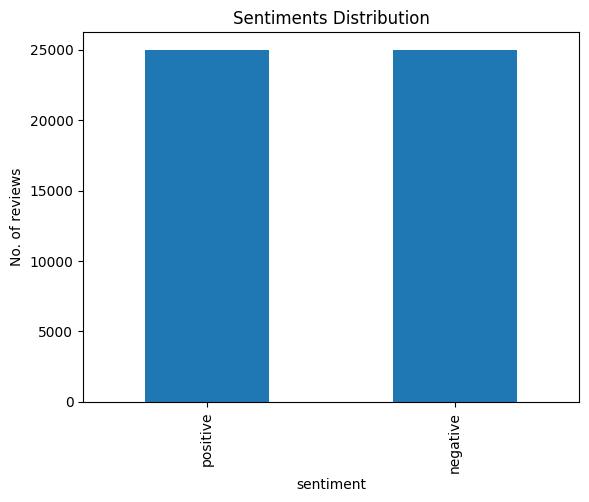

In [32]:
#plot graph

df["sentiment"].value_counts().plot(kind="bar")
plt.title("Sentiments Distribution")
plt.ylabel("No. of reviews")
plt.show()

In [38]:
def clean_text(text):
    text=text.lower()
    text =re.sub(r"<br\s*/?>","",text)
    
    return text


In [39]:
df["clean review"]=df["review"].apply(clean_text)

In [40]:
from sklearn.preprocessing import LabelEncoder
le = LabelEncoder()
df["label"]=le.fit_transform(df["sentiment"])

df.head(2)

,review,sentiment,clean review,label
0,One of the other reviewers has mentioned that ...,positive,one of the other reviewers has mentioned that ...,1
1,A wonderful little production. <br /><br />The...,positive,a wonderful little production. the filming tec...,1


In [41]:
new_df=df[["clean review","label"]]
new_df.head(2)

,clean review,label
0,one of the other reviewers has mentioned that ...,1
1,a wonderful little production. the filming tec...,1


In [43]:
x=new_df["clean review"]
y=new_df["label"]


In [44]:
x_train,x_test,y_train,y_test = train_test_split(x,y,
                                                 test_size=0.2,
                                                 random_state=42)

In [45]:
print(x_train.shape)
x_test.shape

(40000,)


(10000,)

In [ ]:
#vocabulary creation
vocab_size = 10000
t=Tokenizer(
    num_words=vocab_size,
    oov_token="<00V>"
)

t.fit_on_texts(x_train)

x_train_seq = t.texts_to_sequences(x_train)
x_test_seq = t.texts_to_sequences(x_test)



Example token Sequence
[197, 48, 10, 800, 2158, 534, 302, 2, 107, 1904, 2036, 4322, 6544, 3, 812, 4842, 12, 1, 2, 1]


In [47]:
# padding

max_len = 200
x_train_pad=pad_sequences(
    x_train_seq,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

x_test_pad=pad_sequences(
    x_test_seq,
    maxlen=max_len,
    padding="post",
    truncating="post"
)

print("Training data shape:", x_train_pad.shape)
print("Testing data shape:", x_test_pad.shape)

Training data shape: (40000, 200)
Testing data shape: (10000, 200)


In [48]:
#model building

model=Sequential([
    Input(shape=(max_len,)),
    Embedding(input_dim=vocab_size,output_dim=128),
    LSTM(128),
    Dropout(0.4),
    Dense(1,activation="sigmoid")
])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ embedding (Embedding)                │ (None, 200, 128)            │       1,280,000 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ lstm (LSTM)                          │ (None, 128)                 │         131,584 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 128)                 │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 1)                   │             129 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 1,411,713 (5.39 MB)

 Trainable params: 1,411,713 (5.39 MB)

 Non-trainable params: 0 (0.00 B)

In [49]:
#compilation
model.compile(
    optimizer='adam',
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

In [50]:
e_stop= EarlyStopping(
    patience=2
)

In [51]:
#training 
history = model.fit(
    x_train_pad ,y_train,
    epochs= 10,
    batch_size=64,
    validation_split=0.2,
    callbacks=[e_stop]
    
)

Epoch 1/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 92s 181ms/step - accuracy: 0.5338 - loss: 0.6892 - val_accuracy: 0.5268 - val_loss: 0.6897
Epoch 2/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 91s 183ms/step - accuracy: 0.5267 - loss: 0.6930 - val_accuracy: 0.5410 - val_loss: 0.6825
Epoch 3/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 98s 196ms/step - accuracy: 0.6131 - loss: 0.6430 - val_accuracy: 0.5184 - val_loss: 0.6906
Epoch 4/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 87s 174ms/step - accuracy: 0.7724 - loss: 0.4649 - val_accuracy: 0.8500 - val_loss: 0.3559
Epoch 5/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 90s 180ms/step - accuracy: 0.8998 - loss: 0.2613 - val_accuracy: 0.8591 - val_loss: 0.3538
Epoch 6/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 89s 177ms/step - accuracy: 0.9296 - loss: 0.2015 - val_accuracy: 0.8636 - val_loss: 0.3906
Epoch 7/10
500/500 ━━━━━━━━━━━━━━━━━━━━ 94s 187ms/step - accuracy: 0.9517 - loss: 0.1508 - val_accuracy: 0.8545 - val_loss: 0.4523


In [52]:
test_loss , test_accuracy = model.evaluate(x_test_pad,y_test)

print("Test loss: ",test_loss)
print("Test Accuracy: ", test_accuracy)

313/313 ━━━━━━━━━━━━━━━━━━━━ 11s 34ms/step - accuracy: 0.8539 - loss: 0.4498
Test loss:  0.44979730248451233
Test Accuracy:  0.8539000153541565


In [53]:
print("Test Accuracy: ",round(test_accuracy*100),"%")

Test Accuracy:  85 %
